# Blood Donation Prediction

## Project Objective
To predict whether a blood donor will donate blood again in March 2007 using Machine Learning.

## Domain
Healthcare

## Problem Type
Binary Classification

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
print("Hello! Jupyter is working.")

Hello! Jupyter is working.


In [3]:
import urllib.request
import zipfile
import os

url = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1011-BloodDonaPred.zip"

os.makedirs("Dataset", exist_ok=True)

urllib.request.urlretrieve(url, "Dataset/blood_dataset.zip")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [4]:
with zipfile.ZipFile("Dataset/blood_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("Dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [5]:
os.listdir("Dataset")

['.ipynb_checkpoints', 'blood_dataset.zip', 'Data']

In [6]:
os.listdir("Dataset/Data")

['Warm_Up_Predict_Blood_Donations_-_Traning_Data.csv',
 'Warm_Up_Predict_Blood_Donations_-_Traning_Data.xlsx']

In [7]:
import pandas as pd
import numpy as np

print("Pandas imported successfully!")

Pandas imported successfully!


In [8]:
df = pd.read_csv("Dataset/Data/Warm_Up_Predict_Blood_Donations_-_Traning_Data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
df.head()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,619,2,50,12500,98,1
1,664,0,13,3250,28,1
2,441,1,16,4000,35,1
3,160,2,20,5000,45,1
4,358,1,24,6000,77,0


In [10]:
df.tail()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
571,698,23,1,250,23,0
572,433,16,3,750,86,0
573,360,21,2,500,52,0
574,541,39,1,250,39,0
575,74,72,1,250,72,0


In [11]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 576
Number of Columns: 6


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 576 entries, 0 to 575
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Unnamed: 0                   576 non-null    int64
 1   Months since Last Donation   576 non-null    int64
 2   Number of Donations          576 non-null    int64
 3   Total Volume Donated (c.c.)  576 non-null    int64
 4   Months since First Donation  576 non-null    int64
 5   Made Donation in March 2007  576 non-null    int64
dtypes: int64(6)
memory usage: 27.1 KB


In [13]:
df.describe()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
count,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000
mean,374.034722,9.439236,5.427083,1356.770833,34.050347,0.239583
std,216.947773,8.175454,5.740010,1435.002556,24.227672,0.427200
min,0.000000,0.000000,1.000000,250.000000,2.000000,0.000000
25%,183.750000,2.000000,2.000000,500.000000,16.000000,0.000000
50%,375.500000,7.000000,4.000000,1000.000000,28.000000,0.000000
75%,562.500000,14.000000,7.000000,1750.000000,49.250000,0.000000
max,747.000000,74.000000,50.000000,12500.000000,98.000000,1.000000


In [14]:
df.isnull().sum()

Unnamed: 0                     0
Months since Last Donation     0
Number of Donations            0
Total Volume Donated (c.c.)    0
Months since First Donation    0
Made Donation in March 2007    0
dtype: int64

In [15]:
df.isnull().sum().sum()

np.int64(0)

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df['Unnamed: 0'].head()

0    619
1    664
2    441
3    160
4    358
Name: Unnamed: 0, dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.drop(columns=['Unnamed: 0'], inplace=True)

print("Unwanted column removed successfully!")

Unwanted column removed successfully!


In [20]:
df.shape

(576, 5)

In [21]:
df['Made Donation in March 2007'].value_counts()

Made Donation in March 2007
0    438
1    138
Name: count, dtype: int64

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

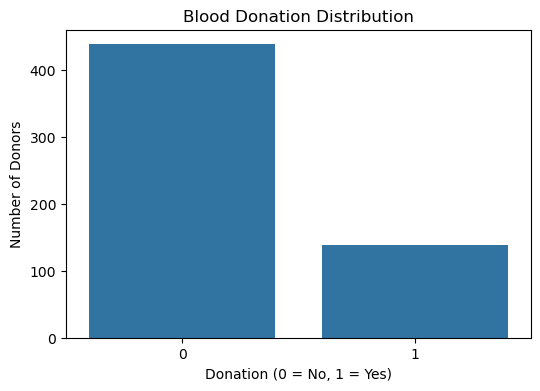

In [23]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Made Donation in March 2007', data=df)

plt.title('Blood Donation Distribution')
plt.xlabel('Donation (0 = No, 1 = Yes)')
plt.ylabel('Number of Donors')

plt.show()

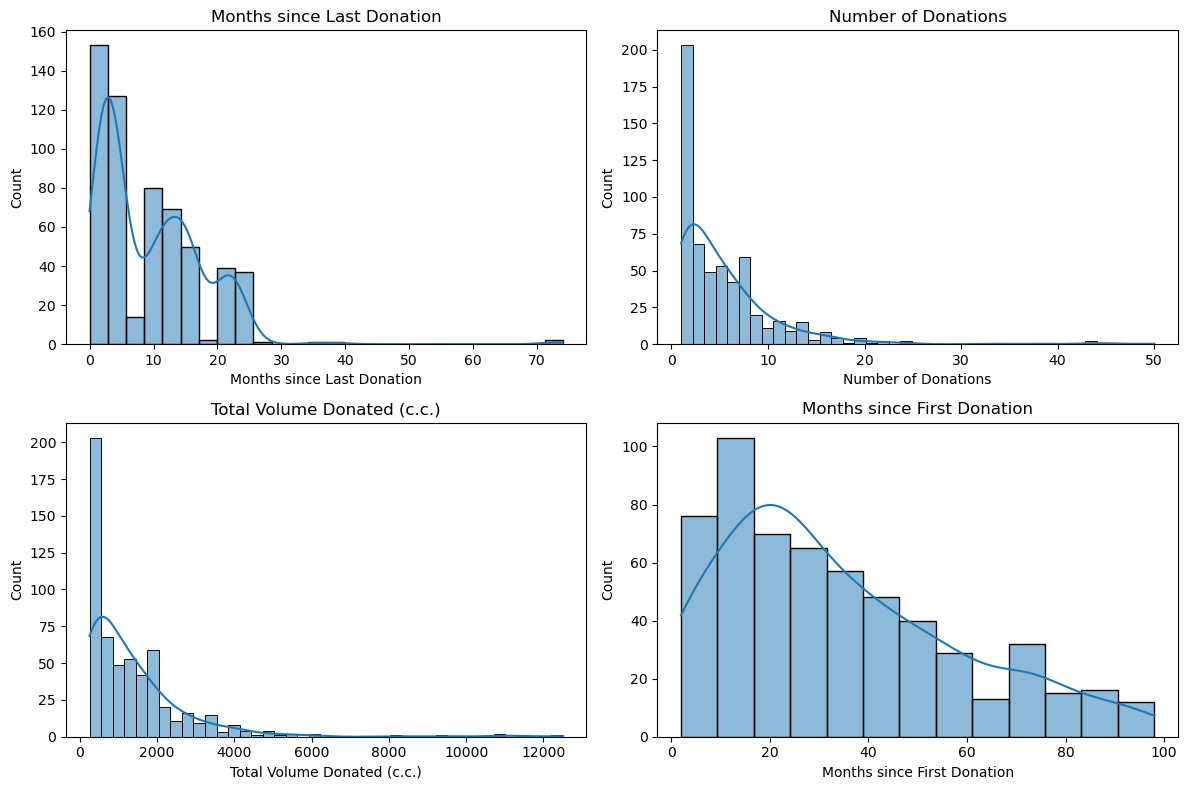

In [24]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(df.columns[:-1]):
    plt.subplot(2, 2, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

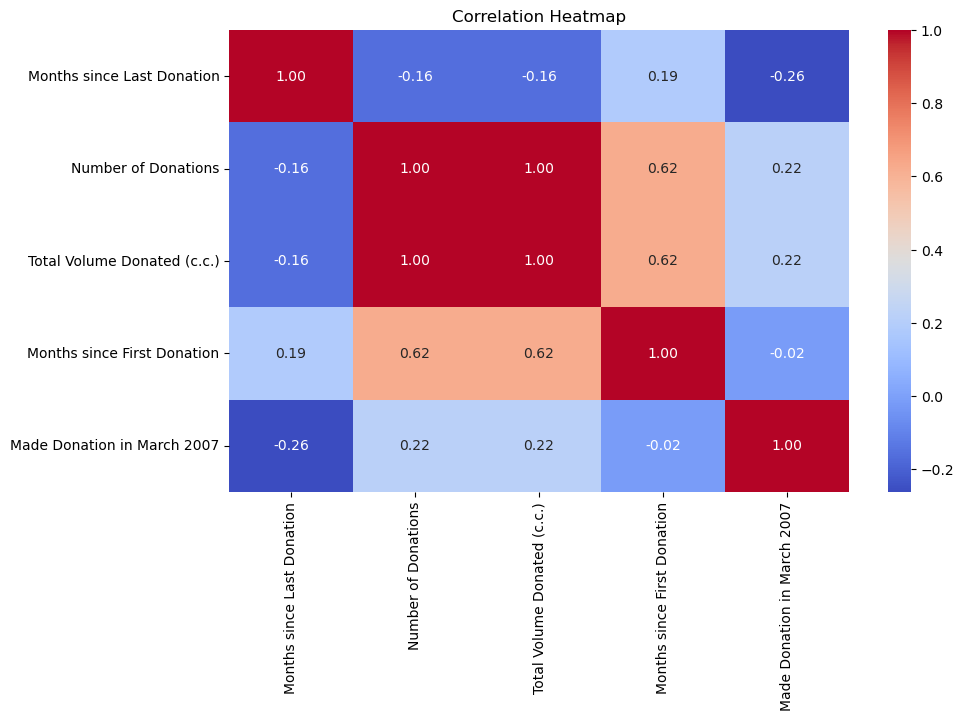

In [25]:
plt.figure(figsize=(10, 6))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

In [26]:
df.corr()['Made Donation in March 2007'].sort_values(ascending=False)

Made Donation in March 2007    1.000000
Number of Donations            0.220615
Total Volume Donated (c.c.)    0.220615
Months since First Donation   -0.019819
Months since Last Donation    -0.261234
Name: Made Donation in March 2007, dtype: float64

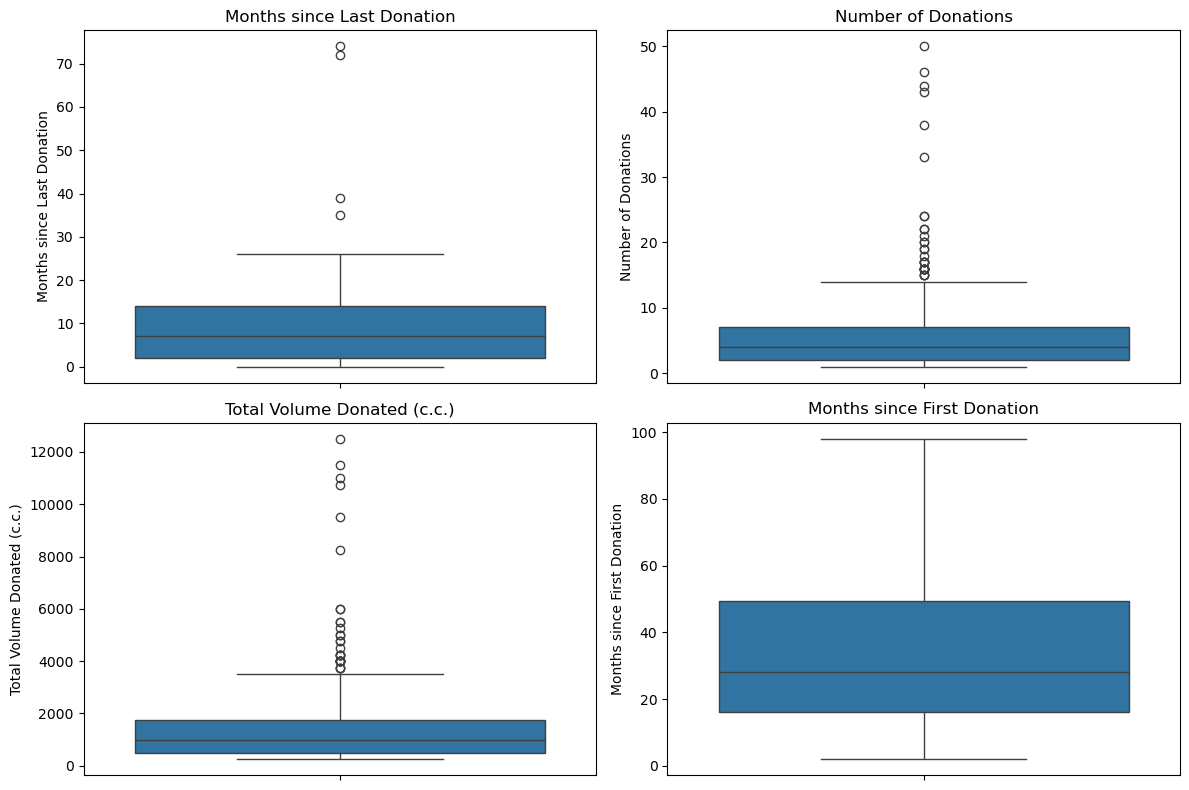

In [27]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(df.columns[:-1]):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Months since Last Donation,576.0,9.439236,8.175454,0.0,2.0,7.0,14.00,74.0
Number of Donations,576.0,5.427083,5.740010,1.0,2.0,4.0,7.00,50.0
Total Volume Donated (c.c.),576.0,1356.770833,1435.002556,250.0,500.0,1000.0,1750.00,12500.0
Months since First Donation,576.0,34.050347,24.227672,2.0,16.0,28.0,49.25,98.0
Made Donation in March 2007,576.0,0.239583,0.427200,0.0,0.0,0.0,0.00,1.0


In [29]:
X = df.drop('Made Donation in March 2007', axis=1)

y = df['Made Donation in March 2007']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (576, 4)
Target shape: (576,)


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (460, 4)
X_test: (116, 4)
y_train: (460,)
y_test: (116,)


In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (460, 4)
Testing data scaled: (116, 4)


In [32]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [33]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("First 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred_lr[:10])

First 10 Actual Values:
[0 0 1 0 1 1 1 0 0 0]

First 10 Predicted Values:
[0 0 0 0 0 1 0 1 0 0]


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Logistic Regression Model Performance")
print("-------------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr, zero_division=0))

Logistic Regression Model Performance
-------------------------------------
Accuracy: 0.7758620689655172
Precision: 0.625
Recall: 0.17857142857142858
F1 Score: 0.2777777777777778


Confusion Matrix:
[[85  3]
 [23  5]]


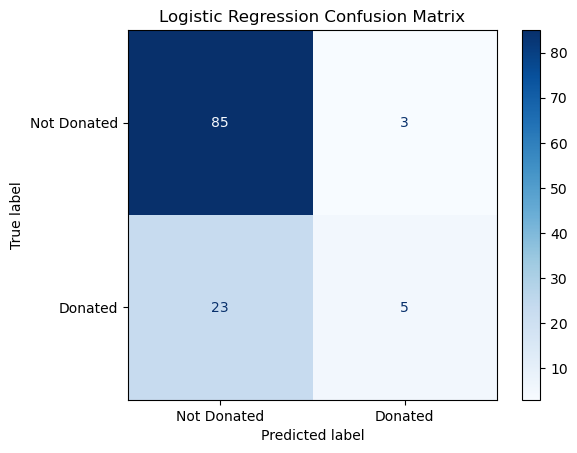

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Donated', 'Donated']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [36]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [37]:
y_pred_dt = dt_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred_dt[:10])

First 10 Actual Values:
[0 0 1 0 1 1 1 0 0 0]

First 10 Predicted Values:
[0 0 1 0 0 1 0 1 0 0]


In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Decision Tree Model Performance")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dt, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_dt, zero_division=0))

Decision Tree Model Performance
--------------------------------
Accuracy: 0.75
Precision: 0.48
Recall: 0.42857142857142855
F1 Score: 0.4528301886792453


In [39]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [40]:
y_pred_rf = rf_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred_rf[:10])

First 10 Actual Values:
[0 0 1 0 1 1 1 0 0 0]

First 10 Predicted Values:
[0 0 1 0 0 1 0 1 0 0]


In [41]:
print("Random Forest Model Performance")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_rf, zero_division=0))

Random Forest Model Performance
--------------------------------
Accuracy: 0.7672413793103449
Precision: 0.5294117647058824
Recall: 0.32142857142857145
F1 Score: 0.4


In [42]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_dt, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_dt, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.775862,0.625000,0.178571,0.277778
1,Decision Tree,0.750000,0.480000,0.428571,0.452830
2,Random Forest,0.767241,0.529412,0.321429,0.400000


In [43]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [44]:
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN Model Performance")
print("----------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_knn, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_knn, zero_division=0))

KNN Model Performance
----------------------
Accuracy: 0.7413793103448276
Precision: 0.4166666666666667
Recall: 0.17857142857142858
F1 Score: 0.25


In [45]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_knn)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_dt, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_knn, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_knn, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_dt, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_knn, zero_division=0)
    ]
})

results.sort_values(by='F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.750000,0.480000,0.428571,0.452830
2,Random Forest,0.767241,0.529412,0.321429,0.400000
0,Logistic Regression,0.775862,0.625000,0.178571,0.277778
3,KNN,0.741379,0.416667,0.178571,0.250000


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 6],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Parameters:", dt_grid.best_params_)
print("Best Cross Validation F1 Score:", dt_grid.best_score_)

In [ ]:
best_dt_model = dt_grid.best_estimator_

y_pred_tuned = best_dt_model.predict(X_test)

print("Tuned Decision Tree Performance")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_tuned, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_tuned, zero_division=0))

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Final Model: Decision Tree")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['Not Donated', 'Donated']
))

cm = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Donated', 'Donated']
)

disp.plot(cmap='Blues')
plt.title('Final Decision Tree Confusion Matrix')
plt.show()

In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance)

plt.figure(figsize=(8, 5))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance
)

plt.title('Decision Tree Feature Importance')
plt.show()


# 11. Final Project Conclusion

The objective of this project was to predict whether a blood donor would donate blood during the next blood donation campaign in March 2007.

In this project, we performed data cleaning, exploratory data analysis, feature analysis, model building, and model evaluation.

We implemented and compared four machine learning algorithms:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors (KNN)

After comparing the models, the Decision Tree model achieved the best F1-score of 45.28% and recall of 42.86% among the tested models.

The model achieved an accuracy of 75%.

Feature importance analysis showed that Months since Last Donation was the most important feature for predicting donor behaviour.

Overall, the Decision Tree model was selected as the final model because it provided the best balance of recall and F1-score among the tested models.



# 12. Challenges Faced and Solutions

During this project, we faced the following challenges:

### 1. Imbalanced Dataset
The dataset contained 438 non-donors and 138 donors.

**Solution:** We used stratified train-test splitting to maintain the target class distribution in both training and testing datasets. We also evaluated models using Precision, Recall, and F1-score instead of relying only on accuracy.

### 2. Small Dataset
The dataset contained only 576 records, which made model training and evaluation challenging.

**Solution:** We used a 5-fold cross-validation approach during hyperparameter tuning to evaluate model performance more reliably.

### 3. Different Feature Scales
The numerical features had different ranges, which could affect distance-based and linear machine learning algorithms.

**Solution:** We applied StandardScaler to Logistic Regression and KNN models. Tree-based models were trained without scaling.

### 4. Model Performance
Different algorithms produced different results. Hyperparameter tuning did not improve the test F1-score of the Decision Tree model.

**Solution:** We compared multiple machine learning algorithms using evaluation metrics and selected the original Decision Tree model based on its comparatively better Recall and F1-score.

### 5. Identifying Important Features
Understanding which attributes influenced donor prediction was important.

**Solution:** We used Decision Tree feature importance to identify the most influential features.

### Conclusion
This project helped us understand data preprocessing, exploratory data analysis, classification algorithms, model evaluation, and hyperparameter tuning. Further improvements could include handling class imbalance using resampling techniques and testing additional machine learning models.
